# Quanto custa usar IA dentro de uma aplicação?

**Atividade — IA aplicada e IA experimental (Prof. Wagner, 3º ciclo)**

## 1. O problema

O uso de IA generativa numa aplicação é cobrado (e medido) em **tokens**: tokens de entrada (o prompt que a aplicação envia) e tokens de saída (a resposta que o modelo gera). O token de saída costuma ser bem mais caro que o de entrada.

Quem coloca IA dentro de um produto precisa responder, antes de lançar:

> **Dado o que o usuário vai perguntar, quantos tokens o modelo vai gerar, e quanto isso vai custar por mês?**

O tamanho do prompt a aplicação conhece. O tamanho da resposta ela **não** conhece. É isso que o algoritmo tenta prever.

## 2. A técnica e a família de algoritmos

- **Técnica:** inferir (prever) o número de tokens da resposta a partir de características do prompt, comparar com uma referência ingênua (baseline) e avaliar o impacto no custo.
- **Família:** **aprendizado supervisionado, regressão**. Comparamos:
  1. *Baseline*: sempre chutar a mediana (não usa nenhuma informação do prompt);
  2. *Regressão linear*;
  3. *Gradient Boosting* (árvores de decisão em sequência).
- Para o custo mensal usamos **simulação de Monte Carlo (bootstrap)**, que dá uma faixa de valores e não um número só.

## 3. Os dados

**OpenAssistant Conversations (oasst1)**: base pública com ~88 mil mensagens reais de conversas entre pessoas e um assistente, em vários idiomas, inclusive pt-BR. Licença Apache 2.0. Fonte: <https://huggingface.co/datasets/OpenAssistant/oasst1>.

Cada resposta do assistente aponta para a mensagem da pessoa que ela responde (`parent_id`). Montamos pares **prompt → melhor resposta** (`rank == 0`).

Os tokens são contados com o tokenizador público **`o200k_base`** (`tiktoken`). Cada modelo tem o seu tokenizador, então os números são uma aproximação realista, não o valor exato de um fornecedor específico.

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RAW = Path("data/raw/oasst_ready.messages.jsonl.gz")
URL = "https://huggingface.co/datasets/OpenAssistant/oasst1/resolve/main/2023-04-12_oasst_ready.messages.jsonl.gz"

if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(URL, RAW)

msgs = pd.read_json(RAW, lines=True)
print(f"{len(msgs):,} mensagens")
msgs.role.value_counts()

88,838 mensagens


role
assistant    55668
prompter     33170
Name: count, dtype: int64

In [2]:
enc = tiktoken.get_encoding("o200k_base")
msgs["tokens"] = [len(t) for t in enc.encode_batch(msgs.text.tolist(), disallowed_special=())]
msgs["chars"] = msgs.text.str.len()

por_id = msgs.set_index("message_id")
resp = msgs[(msgs.role == "assistant") & (msgs["rank"] == 0)]
prompt = por_id.loc[resp.parent_id]

pares = pd.DataFrame({
    "lang": resp.lang.values,
    "prompt_tokens": prompt.tokens.values,
    "resp_tokens": resp.tokens.values,
    # características do prompt que a aplicação conhece antes de chamar o modelo
    "tem_codigo": prompt.text.str.contains(r"```|def |function|código|code", case=False).values.astype(int),
    "perguntas": prompt.text.str.count(r"\?").values,
    "continuacao": prompt.parent_id.notna().values.astype(int),  # 1 = não é a primeira mensagem da conversa
})
pares.to_csv("data/pares_prompt_resposta.csv", index=False)
print(f"{len(pares):,} pares prompt → resposta")
pares.describe().round(1)

18,924 pares prompt → resposta


,prompt_tokens,resp_tokens,tem_codigo,perguntas,continuacao
count,18924.0,18924.0,18924.0,18924.0,18924.0
mean,27.2,199.6,0.0,0.7,0.5
std,53.5,189.4,0.2,0.8,0.5
min,1.0,1.0,0.0,0.0,0.0
25%,11.0,70.0,0.0,0.0,0.0
50%,16.0,159.0,0.0,1.0,0.0
75%,28.0,281.0,0.0,1.0,1.0
max,2371.0,4588.0,1.0,30.0,1.0


## 4. Exploração: os dados fazem sentido?

Antes de modelar, conferimos se os números são coerentes:
- distribuição de tokens do prompt e da resposta;
- relação entre o tamanho do prompt e o tamanho da resposta;
- quanto cada idioma "gasta" de tokens (o mesmo texto em idiomas diferentes custa diferente).

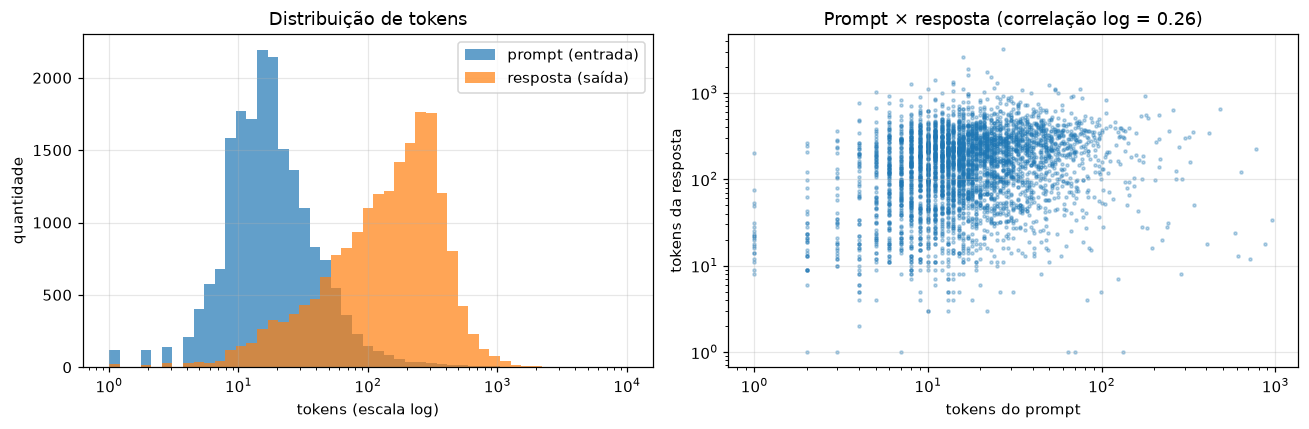

Mediana prompt: 16.0 | mediana resposta: 159.0
A resposta é, em mediana, 9.9 vezes maior que o prompt.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
bins = np.logspace(0, 4, 50)
ax[0].hist(pares.prompt_tokens, bins=bins, alpha=.7, label="prompt (entrada)")
ax[0].hist(pares.resp_tokens, bins=bins, alpha=.7, label="resposta (saída)")
ax[0].set_xscale("log"); ax[0].set_xlabel("tokens (escala log)"); ax[0].set_ylabel("quantidade"); ax[0].legend()
ax[0].set_title("Distribuição de tokens")

amostra = pares.sample(4000, random_state=0)
ax[1].scatter(amostra.prompt_tokens, amostra.resp_tokens, s=4, alpha=.3)
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("tokens do prompt"); ax[1].set_ylabel("tokens da resposta")
corr = np.corrcoef(np.log1p(pares.prompt_tokens), np.log1p(pares.resp_tokens))[0, 1]
ax[1].set_title(f"Prompt × resposta (correlação log = {corr:.2f})")
plt.tight_layout(); plt.savefig(FIG / "01_distribuicao_tokens.png"); plt.show()

print("Mediana prompt:", pares.prompt_tokens.median(), "| mediana resposta:", pares.resp_tokens.median())
print("A resposta é, em mediana,", round(pares.resp_tokens.median() / pares.prompt_tokens.median(), 1), "vezes maior que o prompt.")

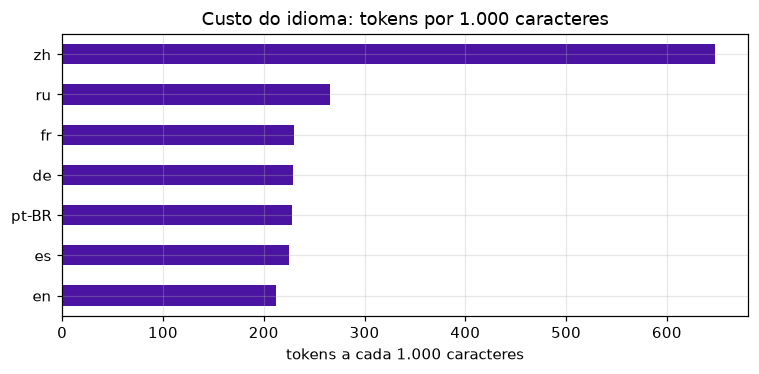

,tokens,chars,tokens_por_1000_caracteres
lang,,,
en,4689183,22112512,212.1
es,3077528,13691563,224.8
pt-BR,139475,612313,227.8
de,296905,1295720,229.1
fr,210294,913927,230.1
ru,838238,3159838,265.3
zh,386592,596492,648.1


In [4]:
idiomas = ["en", "es", "pt-BR", "fr", "de", "ru", "zh"]
tpc = (msgs[msgs.lang.isin(idiomas)]
       .groupby("lang")[["tokens", "chars"]].sum()
       .assign(tokens_por_1000_caracteres=lambda d: 1000 * d.tokens / d.chars)
       .loc[idiomas]
       .sort_values("tokens_por_1000_caracteres"))

ax = tpc.tokens_por_1000_caracteres.plot.barh(figsize=(7, 3.5), color="#4b13a1")
ax.set_xlabel("tokens a cada 1.000 caracteres"); ax.set_ylabel("")
ax.set_title("Custo do idioma: tokens por 1.000 caracteres")
plt.tight_layout(); plt.savefig(FIG / "02_tokens_por_idioma.png"); plt.show()
tpc.round(1)

**Leitura:** as respostas são maiores que os prompts (e o token de saída é o mais caro), a relação entre tamanho do prompt e tamanho da resposta existe mas é **fraca**, e o idioma muda o custo: o mesmo volume de texto em português gasta mais tokens que em inglês.

## 5. O algoritmo: prever os tokens da resposta

- **Entrada (X):** log dos tokens do prompt, se o prompt fala de código, número de perguntas, se é continuação de conversa e o idioma.
- **Saída (y):** log dos tokens da resposta. O log é usado porque a distribuição é muito assimétrica (poucas respostas enormes).
- **Validação:** 75% dos pares para treino, 25% para teste. O modelo nunca vê o teste durante o treino.

In [5]:
X = pd.DataFrame({
    "log_prompt_tokens": np.log1p(pares.prompt_tokens),
    "tem_codigo": pares.tem_codigo,
    "perguntas": pares.perguntas,
    "continuacao": pares.continuacao,
})
for l in idiomas:
    X["idioma_" + l] = (pares.lang == l).astype(int)
y_log = np.log1p(pares.resp_tokens)

X_tr, X_te, y_tr, y_te, r_tr, r_te = train_test_split(
    X, y_log, pares.resp_tokens, test_size=0.25, random_state=42)

modelos = {
    "Baseline (mediana)": None,
    "Regressão linear": LinearRegression(),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}
linhas, previsoes = [], {}
for nome, m in modelos.items():
    if m is None:
        p_log = np.full(len(y_te), np.median(y_tr))
        fator = np.mean(np.exp(y_tr - np.median(y_tr)))
    else:
        m.fit(X_tr, y_tr)
        p_log = m.predict(X_te)
        # correção de "smearing": volta do log para a escala real sem subestimar a média
        fator = np.mean(np.exp(y_tr - m.predict(X_tr)))
    previsoes[nome] = np.expm1(p_log) * fator
    linhas.append({
        "modelo": nome,
        "R² (log)": r2_score(y_te, p_log),
        "erro médio por resposta (tokens)": mean_absolute_error(r_te, np.expm1(p_log)),
        "total previsto / total real": previsoes[nome].sum() / r_te.sum(),
    })
resultado = pd.DataFrame(linhas).set_index("modelo").round(3)
resultado

,R² (log),erro médio por resposta (tokens),total previsto / total real
modelo,,,
Baseline (mediana),-0.029,123.790,0.997
Regressão linear,0.116,119.710,1.038
Gradient Boosting,0.151,117.157,1.022


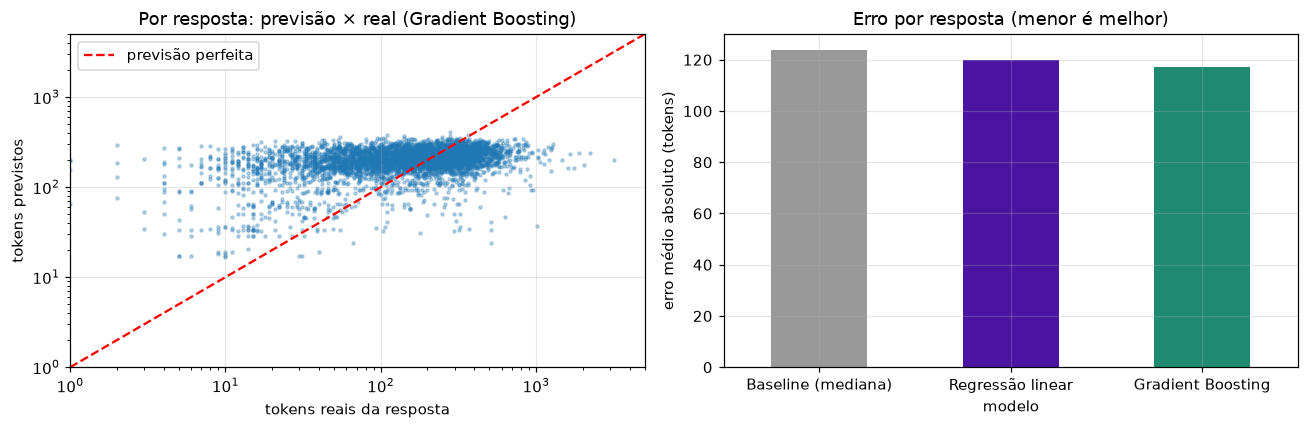

In [6]:
gb = previsoes["Gradient Boosting"]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(r_te, gb, s=4, alpha=.3)
lim = [1, 5000]
ax[0].plot(lim, lim, "r--", label="previsão perfeita")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("tokens reais da resposta"); ax[0].set_ylabel("tokens previstos")
ax[0].set_title("Por resposta: previsão × real (Gradient Boosting)"); ax[0].legend()

resultado["erro médio por resposta (tokens)"].plot.bar(ax=ax[1], color=["#999", "#4b13a1", "#1f8a70"], rot=0)
ax[1].set_ylabel("erro médio absoluto (tokens)"); ax[1].set_title("Erro por resposta (menor é melhor)")
plt.tight_layout(); plt.savefig(FIG / "03_previsto_vs_real.png"); plt.show()

**Leitura:** prever o tamanho de **uma** resposta é difícil. O Gradient Boosting explica só ~15% da variação (R²) e erra em média ~117 tokens por resposta, pouco melhor que o baseline. Isso é um resultado **válido e importante**: o tamanho da resposta depende muito do conteúdo, e não só do tamanho da pergunta.

Mas a aplicação não paga uma resposta, paga **milhares**. Na soma, os erros para cima e para baixo se compensam: a coluna "total previsto / total real" fica perto de 1 para todos os métodos, **inclusive o baseline**. Ou seja: para o total, uma média histórica bem medida já resolve. O modelo só agrega quando é preciso diferenciar requisições (ex.: prompts com código geram respostas maiores).

## 6. Impacto: quanto custa por mês?

Simulamos uma aplicação com **N requisições por mês**. Em cada simulação (Monte Carlo / bootstrap) sorteamos N conversas reais da base de teste e somamos os tokens. Repetindo 2.000 vezes, temos uma **faixa** de custo, e não um número só.

Os preços são **parâmetros de exemplo** em US$ por 1 milhão de tokens. Basta trocar pelos do modelo que a aplicação usa.

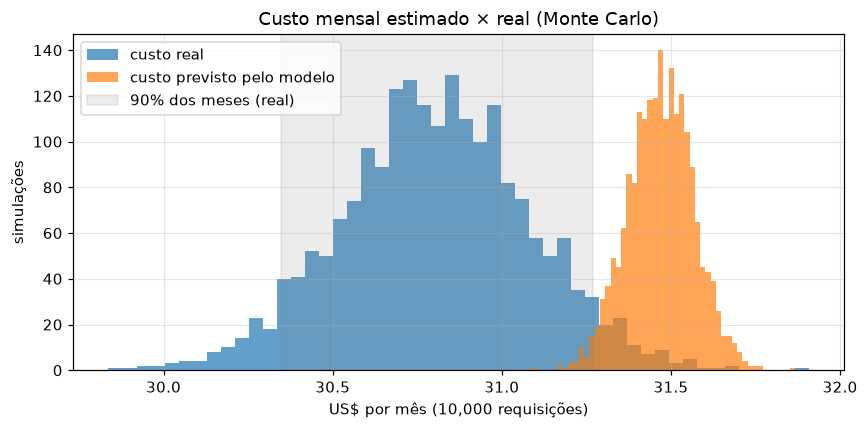

Custo real: mediana US$ 30.80 | 90% dos meses entre US$ 30.35 e US$ 31.27
Custo previsto: mediana US$ 31.47
Erro da previsão no total do mês: 2.2% (mediana)
Parte do custo que vem da saída: 97%


In [7]:
PRECO_ENTRADA = 3.00   # US$ por 1M tokens de entrada (exemplo, editável)
PRECO_SAIDA = 15.00    # US$ por 1M tokens de saída (exemplo, editável)
REQ_POR_MES = 10_000
SIMULACOES = 2_000

teste = pares.loc[X_te.index].assign(prev_saida=gb)
rng = np.random.default_rng(42)
idx = rng.integers(0, len(teste), size=(SIMULACOES, REQ_POR_MES))
ent = teste.prompt_tokens.values[idx].sum(1)
sai_real = teste.resp_tokens.values[idx].sum(1)
sai_prev = teste.prev_saida.values[idx].sum(1)

custo_real = (ent * PRECO_ENTRADA + sai_real * PRECO_SAIDA) / 1e6
custo_prev = (ent * PRECO_ENTRADA + sai_prev * PRECO_SAIDA) / 1e6

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(custo_real, bins=50, alpha=.7, label="custo real")
ax.hist(custo_prev, bins=50, alpha=.7, label="custo previsto pelo modelo")
p5, p95 = np.percentile(custo_real, [5, 95])
ax.axvspan(p5, p95, color="grey", alpha=.15, label="90% dos meses (real)")
ax.set_xlabel(f"US$ por mês ({REQ_POR_MES:,} requisições)"); ax.set_ylabel("simulações")
ax.set_title("Custo mensal estimado × real (Monte Carlo)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_custo_mensal.png"); plt.show()

print(f"Custo real: mediana US$ {np.median(custo_real):.2f} | 90% dos meses entre US$ {p5:.2f} e US$ {p95:.2f}")
print(f"Custo previsto: mediana US$ {np.median(custo_prev):.2f}")
print(f"Erro da previsão no total do mês: {100 * np.median(np.abs(custo_prev - custo_real) / custo_real):.1f}% (mediana)")
print(f"Parte do custo que vem da saída: {100 * np.median(sai_real * PRECO_SAIDA / (custo_real * 1e6)):.0f}%")

## 7. Estamos fazendo algo válido?

**O que valida o resultado**
- Os dados são reais e públicos (conversas humanas com um assistente), não inventados.
- O modelo foi avaliado em dados que **não viu no treino**.
- Comparamos com um **baseline**: o modelo só "vale" na medida em que bate o chute ingênuo, e mostramos que, por resposta, ele bate só por pouco.
- O custo vem de uma simulação com muitas repetições, o que dá uma faixa de confiança.

**Limitações (honestas)**
- O tokenizador `o200k_base` é uma aproximação: cada fornecedor conta tokens de um jeito um pouco diferente.
- As respostas da base são de voluntários (oasst1), não de um modelo comercial, que pode ser mais ou menos "falante".
- Os preços são exemplos e mudam com o tempo e com o modelo.
- O custo real de uma aplicação também inclui o *system prompt* e o histórico da conversa, que repetem tokens de entrada a cada chamada.

## 8. Conclusão

1. **Prever uma resposta individual é pouco confiável** (R² ≈ 0,15). O tamanho da resposta depende do conteúdo, não só do tamanho da pergunta.
2. **Prever o custo agregado funciona bem**: somando 10 mil requisições, a estimativa fica a ~2% do custo real. Mas o baseline (média histórica) chega no mesmo resultado. Para orçamento, o essencial é **medir** os tokens de uma amostra real de uso. O modelo mais sofisticado não muda o total, só ajuda a entender *quais* requisições custam mais.
3. **A saída domina o custo**: as respostas são maiores que os prompts e o token de saída é mais caro. Limitar o tamanho das respostas (`max_tokens`, instruções de concisão) é a alavanca de economia mais forte.
4. **Idioma importa**: português gasta ~7% mais tokens por caractere que inglês (e chinês, ~3x). A mesma aplicação custa um pouco mais para usuários brasileiros.